<a href="https://colab.research.google.com/github/Mohamed-ktari/advanced-signal/blob/main/TPSA_KF_Mohamed_ktari.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [117]:
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt
import time

In [82]:
def update_Kfilter(R_eps, A, C, Rv, Rb):
    d = R_eps.shape[0]

    S = C @ R_eps @ C.conj().T + Rb
    G = R_eps @ C.conj().T @ np.linalg.inv(S)

    R_eps_Ge = (np.eye(d) - G @ C) @ R_eps

    R_eps_next = A @ R_eps_Ge @ A.conj().T + Rv

    return G, R_eps_next

In [83]:
x=np.ones(2)
x=x[:, None]
x.shape

(2, 1)

In [84]:
def Kal_predict(x, z0, R0, A, C, Rv, Rb):
    x = np.asarray(x, dtype=float)
    if x.ndim == 1:
        x = x[:, None]
    N, m = x.shape
    d = len(z0)

    z_hat = np.zeros((N + 1, d))
    x_hat = np.zeros((N + 1, m))
    G_all = np.zeros((N, d, m))
    R_all = np.zeros((N + 1, d, d))

    z_hat[0] = z0
    x_hat[0] = C @ z0
    R = R0.copy()
    R_all[0] = R

    for n in range(N):
        G, R_next = update_Kfilter(R, A, C, Rv, Rb)
        e = x[n] - C @ z_hat[n]
        z_hat[n + 1] = A @ (z_hat[n] + G @ e)
        x_hat[n + 1] = C @ z_hat[n + 1]

        G_all[n] = G
        R = R_next
        R_all[n + 1] = R

    return z_hat, x_hat, G_all, R_all

In [85]:

data = loadmat("reservoir1.mat")
y = np.asarray(data["y"]).flatten()
N = len(y)
print("Number of measurements:", N)

Number of measurements: 100


In [89]:
A = np.array([[1.0]])
C = np.array([[1.0]])
Rv = np.array([[0.0]])
Rb = np.array([[(1)]])

In [90]:
configs = [
    {"z0": y[0], "R0": 1.0,   "label": "z0=y[0], R0=1"},
    {"z0": 0.0,  "R0": 1.0,   "label": "z0=0, R0=1"},
    {"z0": 0.0,  "R0": 1e-3,  "label": "z0=0, R0=1e-3"},
    {"z0": 0.0,  "R0": 1e3,   "label": "z0=0, R0=1e3"},
]

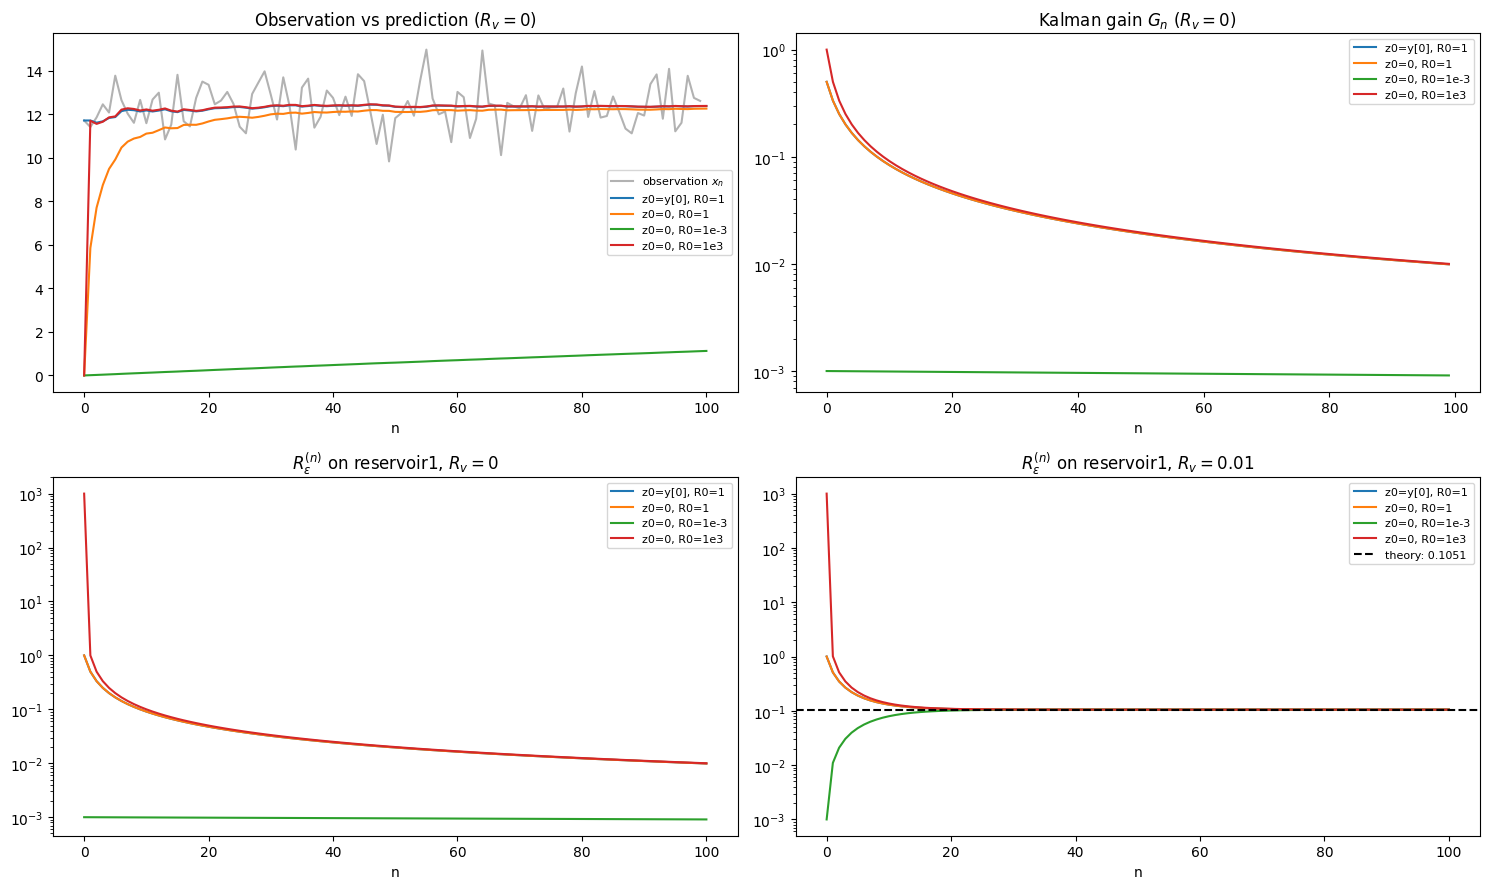

R_eps (Rv>0) at n=50, 100: 0.10513404980628036 0.10512492238861629
Theoretical limit        : 0.10512492197250393


In [91]:

Rv0 = np.array([[0.0]])
Rv_pos = 1e-2
Rvp = np.array([[Rv_pos]])
R_inf = (Rv_pos + np.sqrt(Rv_pos**2 + 4 * Rv_pos * Rb[0, 0])) / 2
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

ax[0, 0].plot(y, color="gray", alpha=0.6, label="observation $x_n$")

for cfg in configs:
    z0 = np.array([cfg["z0"]])
    R0 = np.array([[cfg["R0"]]])


    z_hat, x_hat, G, R_all = Kal_predict(y, z0, R0, A, C, Rv0, Rb)
    ax[0, 0].plot(x_hat[:, 0], label=cfg["label"])
    ax[0, 1].plot(G[:, 0, 0], label=cfg["label"])
    ax[1, 0].plot(R_all[:, 0, 0], label=cfg["label"])


    _, _, _, R_all_p = Kal_predict(y, z0, R0, A, C, Rvp, Rb)
    ax[1, 1].plot(R_all_p[:, 0, 0], label=cfg["label"])

ax[1, 1].axhline(R_inf, color="k", ls="--", label=f"theory: {R_inf:.4f}")

ax[0, 0].set_title("Observation vs prediction ($R_v = 0$)")
ax[0, 1].set_title("Kalman gain $G_n$ ($R_v = 0$)")
ax[1, 0].set_title("$R_\\varepsilon^{(n)}$ on reservoir1, $R_v = 0$")
ax[1, 1].set_title(f"$R_\\varepsilon^{{(n)}}$ on reservoir1, $R_v = {Rv_pos}$")

for a in ax.ravel():
    a.set_xlabel("n")
    a.legend(fontsize=8)
for a in (ax[0, 1], ax[1, 0], ax[1, 1]):
    a.set_yscale("log")

plt.tight_layout()
plt.show()


print("R_eps (Rv>0) at n=50, 100:", R_all_p[50, 0, 0], R_all_p[100, 0, 0])
print("Theoretical limit        :", R_inf)

In [98]:
data2 = loadmat("reservoir2.mat")
y2 = np.asarray(data2["y"]).flatten()
N2 = len(y2)
print("Number of measurements:", N2)

Number of measurements: 100


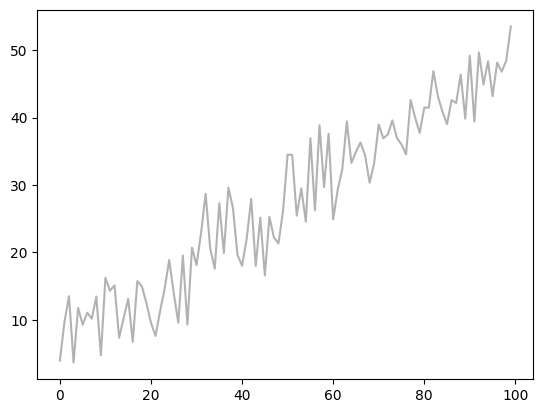

In [99]:
plt.plot(y2, color="gray", alpha=0.6, label="observation $x_n$")

In [100]:
A2 = np.array([[1.0, 1.0],
               [0.0, 1.0]])
C2 = np.array([[1.0, 0.0]])
Rv2 = 1e-6 * np.eye(2)
#Rb2 = np.array([[np.var(np.diff(y2) - np.mean(np.diff(y2))) / 2]])
Rb2 = np.array(1)

In [101]:
z0_2 = np.array([0.0, 0.0])
#z0_2 = np.array([y2[0], 0.0])
R0_2 = np.diag([1.0, 1.0])
z_hat2, x_hat2, G2, R_all2 = Kal_predict(y2, z0_2, R0_2, A2, C2, Rv2, Rb2)

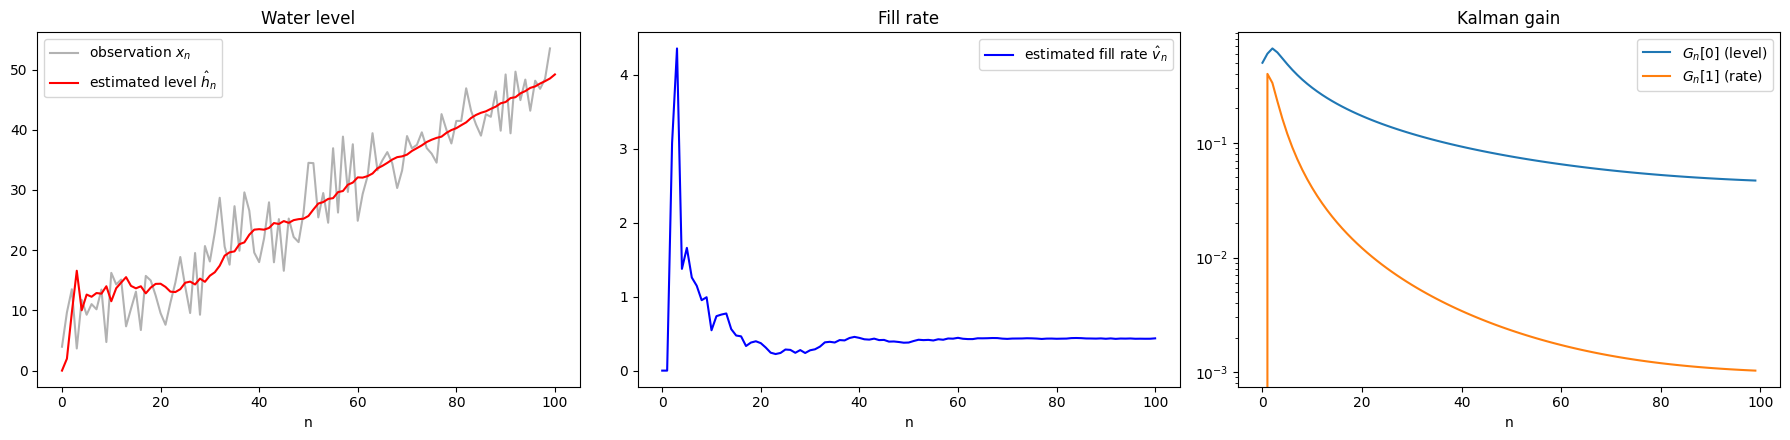

In [102]:
ig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].plot(y2, color="gray", alpha=0.6, label="observation $x_n$")
ax[0].plot(z_hat2[:, 0], "r", label="estimated level $\\hat h_n$")
ax[0].set_title("Water level"); ax[0].set_xlabel("n"); ax[0].legend()

ax[1].plot(z_hat2[:, 1], "b", label="estimated fill rate $\\hat v_n$")

ax[1].set_title("Fill rate"); ax[1].set_xlabel("n"); ax[1].legend()

ax[2].plot(G2[:, 0, 0], label="$G_n[0]$ (level)")
ax[2].plot(G2[:, 1, 0], label="$G_n[1]$ (rate)")
ax[2].set_title("Kalman gain"); ax[2].set_xlabel("n")
ax[2].set_yscale("log"); ax[2].legend()

plt.tight_layout(); plt.show()

In [103]:
final_rate = z_hat2[-1, 1]
tol = 0.05 * abs(final_rate)
outside = np.where(np.abs(z_hat2[:, 1] - final_rate) > tol)[0]
n_conv = outside[-1] + 1 if len(outside) else 0
print("Final level estimate:", z_hat2[-1, 0])
print("Final rate estimate :", final_rate)
print("Rate converges (5% band) after n =", n_conv, "iterations")

dG = np.abs(np.diff(G2[:, 0, 0]))
print("Gain change < 1e-3 from n =", np.where(dG > 1e-3)[0][-1] + 1)

Final level estimate: 49.1847988362426
Final rate estimate : 0.43609811172155977
Rate converges (5% band) after n = 56 iterations
Gain change < 1e-3 from n = 57


In [107]:
data3 = loadmat("cible.mat")
for k, v in data3.items():
    if not k.startswith("__"):
        print(k, np.shape(v))

y (1, 300)
x (2, 300)


In [112]:
dt = 0.2
sigma_a2 = 1.0
sigma_b2 = 10.0

A3 = np.array([[1.0, dt],
               [0.0, 1.0]])
C3 = np.array([[1.0, 0.0]])
Gamma = np.array([[dt**2 / 2], [dt]])
Rv3 = sigma_a2 * Gamma @ Gamma.T
Rb3 = np.array([[sigma_b2]])

In [113]:
y3 = np.asarray(data3["y"], dtype=float).flatten()
z_true = np.asarray(data3["x"], dtype=float).T
N3 = len(y3)
t = np.arange(N3) * dt

In [119]:
z0_3 = np.array([0.0, 0.0])
R0_3 = np.diag([sigma_b2, 10.0])

z_hat3, x_hat3, G3, R_all3 = Kal_predict(y3, z0_3, R0_3, A3, C3, Rv3, Rb3)
z_est = z_hat3[:N3]

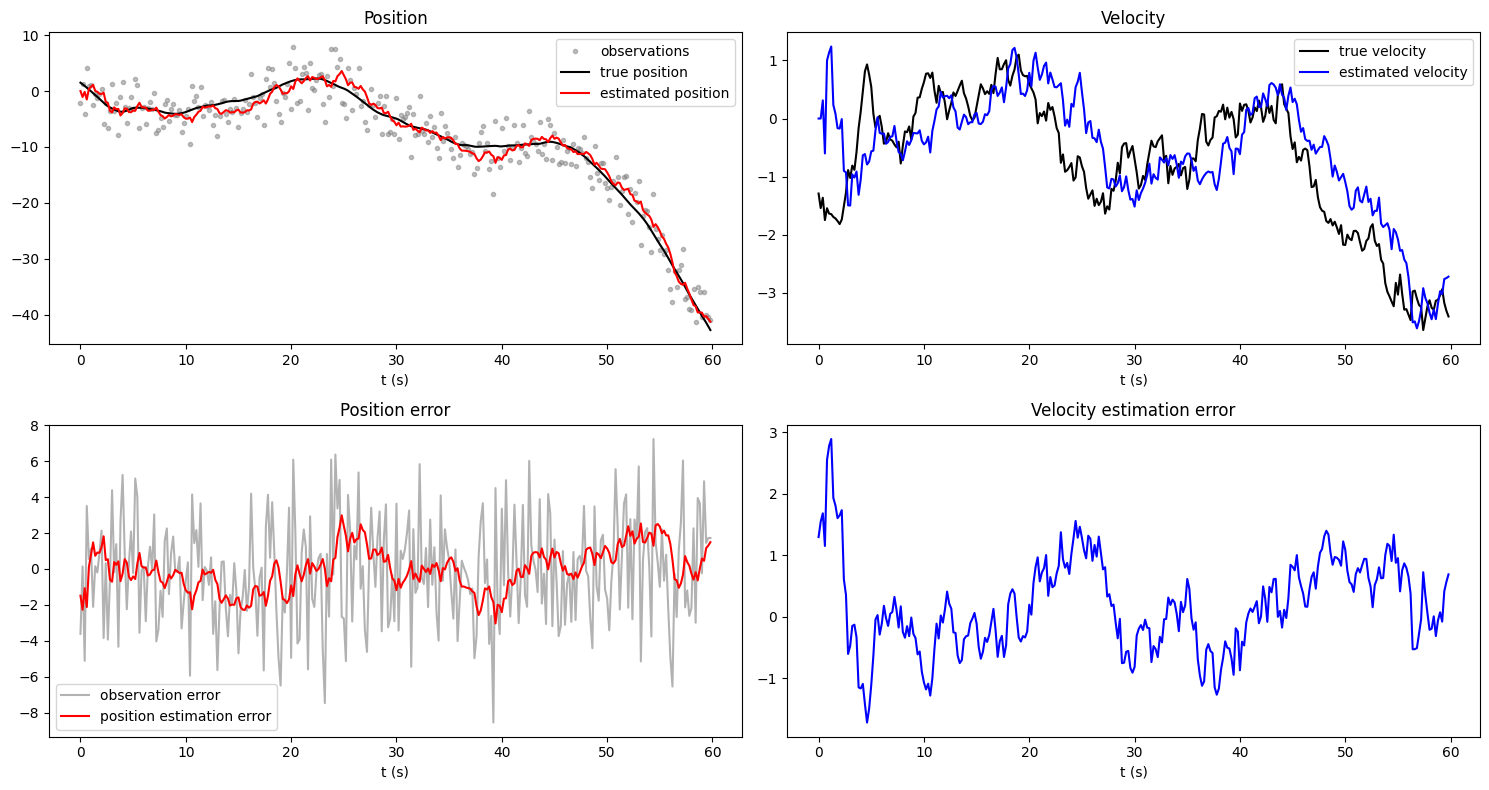

In [120]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))

ax[0, 0].plot(t, y3, ".", color="gray", alpha=0.5, label="observations")
ax[0, 0].plot(t, z_true[:, 0], "k", label="true position")
ax[0, 0].plot(t, z_est[:, 0], "r", label="estimated position")
ax[0, 0].set_title("Position"); ax[0, 0].legend()

ax[0, 1].plot(t, z_true[:, 1], "k", label="true velocity")
ax[0, 1].plot(t, z_est[:, 1], "b", label="estimated velocity")
ax[0, 1].set_title("Velocity"); ax[0, 1].legend()

ax[1, 0].plot(t, y3 - z_true[:, 0], color="gray", alpha=0.6, label="observation error")
ax[1, 0].plot(t, z_est[:, 0] - z_true[:, 0], "r", label="position estimation error")
ax[1, 0].set_title("Position error"); ax[1, 0].legend()

ax[1, 1].plot(t, z_est[:, 1] - z_true[:, 1], "b")
ax[1, 1].set_title("Velocity estimation error")

for a in ax.ravel():
    a.set_xlabel("t (s)")
plt.tight_layout(); plt.show()

R_eps converged (change < 1e-10) from n = 149
R_inf =
 [[1.72352321 0.68479262]
 [0.68479262 0.52337085]]
G_inf = [0.1470141  0.05841184]
RHS of Riccati =
 [[1.72352321 0.68479262]
 [0.68479262 0.52337085]]
||RHS - R_inf||  = 0.0
||update_Kfilter(R_inf) - R_inf|| = 0.0
R0 diag [0.001 0.001] -> ||R_N - R_inf|| = 6.377745716588144e-16
R0 diag [1. 1.] -> ||R_N - R_inf|| = 1.5700924586837752e-16
R0 diag [1000. 1000.] -> ||R_N - R_inf|| = 1.1102230246251565e-16


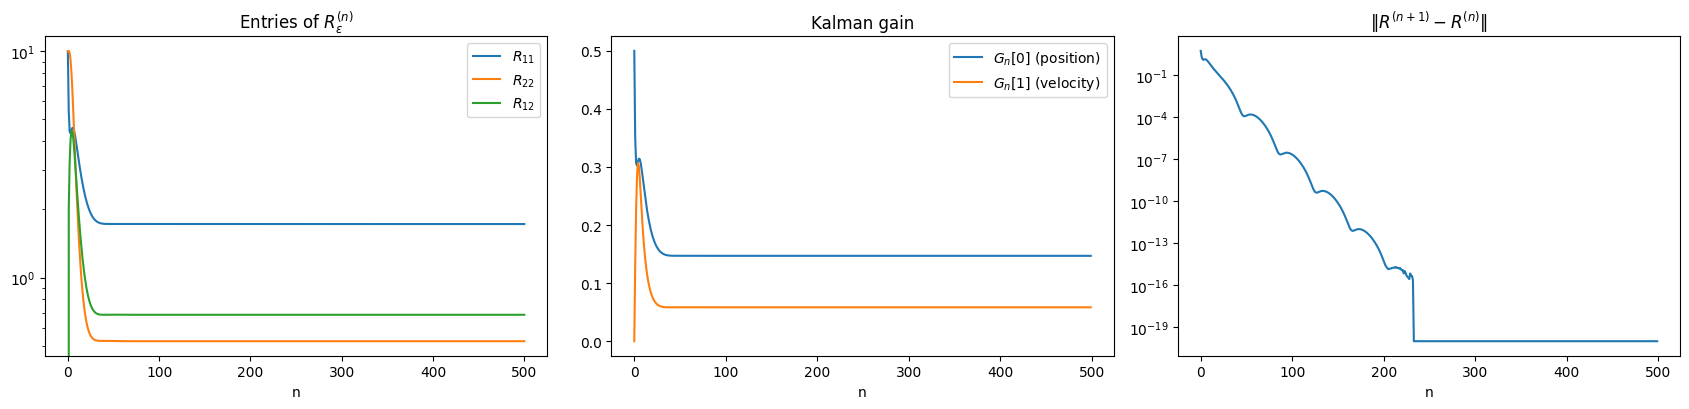

In [121]:

N_big = 500
R = R0_3.copy()
R_hist, G_hist = [R.copy()], []
for n in range(N_big):
    G, R = update_Kfilter(R, A3, C3, Rv3, Rb3)
    R_hist.append(R.copy())
    G_hist.append(G.copy())
R_hist = np.array(R_hist)
G_hist = np.array(G_hist)


dR = np.array([np.linalg.norm(R_hist[n+1] - R_hist[n]) for n in range(N_big)])
dG = np.array([np.linalg.norm(G_hist[n+1] - G_hist[n]) for n in range(N_big-1)])
n_conv = np.where(dR > 1e-10)[0][-1] + 1
print("R_eps converged (change < 1e-10) from n =", n_conv)


R_inf = R_hist[-1]
G_inf, R_next = update_Kfilter(R_inf, A3, C3, Rv3, Rb3)
print("R_inf =\n", R_inf)
print("G_inf =", G_inf.ravel())


I = np.eye(2)
rhs = A3 @ (I - G_inf @ C3) @ R_inf @ A3.T + Rv3
print("RHS of Riccati =\n", rhs)
print("||RHS - R_inf||  =", np.linalg.norm(rhs - R_inf))
print("||update_Kfilter(R_inf) - R_inf|| =", np.linalg.norm(R_next - R_inf))


for R0 in [np.diag([1e-3, 1e-3]), np.diag([1.0, 1.0]), np.diag([1e3, 1e3])]:
    R = R0.copy()
    for n in range(N_big):
        _, R = update_Kfilter(R, A3, C3, Rv3, Rb3)
    print("R0 diag", np.diag(R0), "-> ||R_N - R_inf|| =", np.linalg.norm(R - R_inf))


fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for (i, j, lab) in [(0, 0, "$R_{11}$"), (1, 1, "$R_{22}$"), (0, 1, "$R_{12}$")]:
    ax[0].plot(R_hist[:, i, j], label=lab)
ax[0].set_title("Entries of $R_\\varepsilon^{(n)}$"); ax[0].set_yscale("log"); ax[0].legend()

ax[1].plot(G_hist[:, 0, 0], label="$G_n[0]$ (position)")
ax[1].plot(G_hist[:, 1, 0], label="$G_n[1]$ (velocity)")
ax[1].set_title("Kalman gain"); ax[1].legend()

ax[2].semilogy(dR + 1e-20)
ax[2].set_title("$\\|R^{(n+1)} - R^{(n)}\\|$")
for a in ax: a.set_xlabel("n")
plt.tight_layout(); plt.show()

In [ ]:
def Kal_predict_const(x, z0, A, C, G_inf):
    x = np.asarray(x, dtype=float)
    if x.ndim == 1:
        x = x[:, None]
    N, m = x.shape
    d = len(z0)
    z_hat = np.zeros((N + 1, d))
    x_hat = np.zeros((N + 1, m))
    z_hat[0] = z0
    x_hat[0] = C @ z0
    for n in range(N):
        e = x[n] - C @ z_hat[n]
        z_hat[n + 1] = A @ (z_hat[n] + G_inf @ e)
        x_hat[n + 1] = C @ z_hat[n + 1]
    return z_hat, x_hat

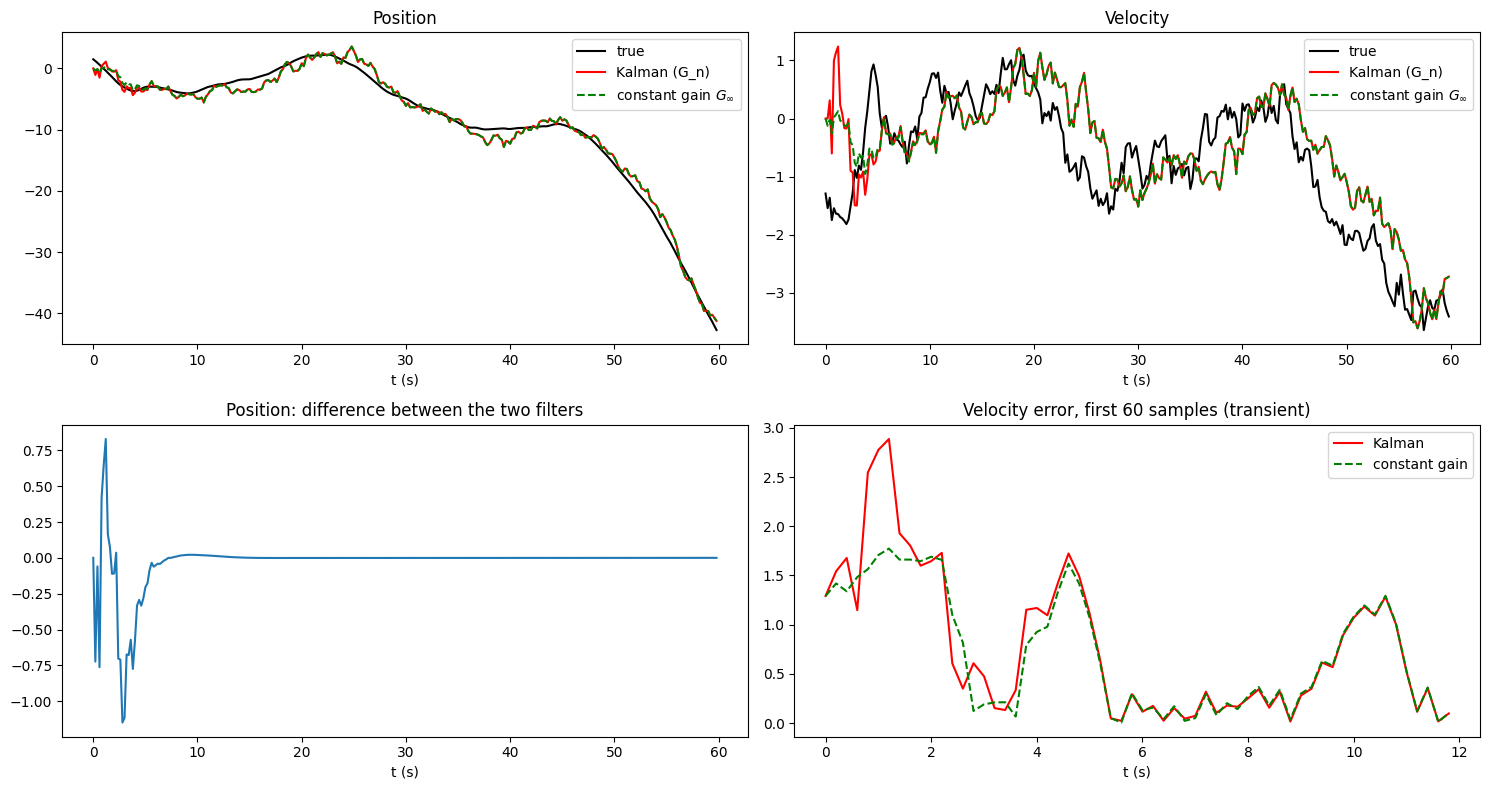

                                Kalman  Const gain
RMSE position (m)                1.168       1.164
RMSE velocity (m/s)              0.764       0.725
RMSE position, n>=50             1.229       1.229
RMSE velocity, n>=50             0.672       0.672
Computation time (s)           0.01671     0.00287
Max |difference| for n>=50 : 0.020143289484098048


In [122]:
t0 = time.perf_counter()
z_kal, x_kal, G_kal, R_kal = Kal_predict(y3, z0_3, R0_3, A3, C3, Rv3, Rb3)
t_kal = time.perf_counter() - t0

t0 = time.perf_counter()
z_cst, x_cst = Kal_predict_const(y3, z0_3, A3, C3, G_inf)
t_cst = time.perf_counter() - t0

zk, zc = z_kal[:N3], z_cst[:N3]


fig, ax = plt.subplots(2, 2, figsize=(15, 8))

ax[0, 0].plot(t, z_true[:, 0], "k", label="true")
ax[0, 0].plot(t, zk[:, 0], "r", label="Kalman (G_n)")
ax[0, 0].plot(t, zc[:, 0], "g--", label="constant gain $G_\\infty$")
ax[0, 0].set_title("Position"); ax[0, 0].legend()

ax[0, 1].plot(t, z_true[:, 1], "k", label="true")
ax[0, 1].plot(t, zk[:, 1], "r", label="Kalman (G_n)")
ax[0, 1].plot(t, zc[:, 1], "g--", label="constant gain $G_\\infty$")
ax[0, 1].set_title("Velocity"); ax[0, 1].legend()

ax[1, 0].plot(t, zk[:, 0] - zc[:, 0])
ax[1, 0].set_title("Position: difference between the two filters")

ax[1, 1].plot(t[:60], np.abs(zk[:60, 1] - z_true[:60, 1]), "r", label="Kalman")
ax[1, 1].plot(t[:60], np.abs(zc[:60, 1] - z_true[:60, 1]), "g--", label="constant gain")
ax[1, 1].set_title("Velocity error, first 60 samples (transient)"); ax[1, 1].legend()

for a in ax.ravel(): a.set_xlabel("t (s)")
plt.tight_layout(); plt.show()


def rmse(a, b): return np.sqrt(np.mean((a - b)**2))

print(f"{'':28s}{'Kalman':>10s}{'Const gain':>12s}")
print(f"{'RMSE position (m)':28s}{rmse(zk[:,0], z_true[:,0]):10.3f}{rmse(zc[:,0], z_true[:,0]):12.3f}")
print(f"{'RMSE velocity (m/s)':28s}{rmse(zk[:,1], z_true[:,1]):10.3f}{rmse(zc[:,1], z_true[:,1]):12.3f}")
k = 50   # skip the transient
print(f"{'RMSE position, n>=50':28s}{rmse(zk[k:,0], z_true[k:,0]):10.3f}{rmse(zc[k:,0], z_true[k:,0]):12.3f}")
print(f"{'RMSE velocity, n>=50':28s}{rmse(zk[k:,1], z_true[k:,1]):10.3f}{rmse(zc[k:,1], z_true[k:,1]):12.3f}")
print(f"{'Computation time (s)':28s}{t_kal:10.5f}{t_cst:12.5f}")
print("Max |difference| for n>=50 :", np.max(np.abs(zk[k:] - zc[k:])))